# 0. Introduction and Problem Definition

## Use case

- **Who would use this model, and for what?** An architect or a small developer in King County doing a feasibility study. They compare design options for a house (size, bedrooms, bathrooms, floors, construction quality) and want a quick estimate of the market value of each option.
- **Which mistake is more expensive?** Over-estimating the price. 
- **What would the user know at prediction time?** The design of the house (living area, bedrooms, bathrooms, floors, basement, grade, condition, year built and renovated) and the plot (lot area, ZIP code and coordinates). 

In [3]:
%pip install -r ../requirements.txt

  Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached pyyaml-6.0.3-cp314-cp314-win_amd64.whl.metadata (2.4 kB)
  Using cached 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Samiha Abeda Nur\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


## Setup

In [4]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib   # to save and load the trained model

### Folder Directory

In [5]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("..") / "data"      # the clean CSV file from Day 1 is here
FIG_DIR = Path("..") / "figures"    # exported plots go here
MODEL_DIR = Path("..") / "models"   # the trained model is saved here
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# Seed for anything random (split, cross-validation, models),
# so we always get the same results.
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## Load the Clean Dataset from Day 1

We start from the clean dataset we produced on Day 1 (`kc_houses_data_clean.csv`). On Day 1 we:

- converted the `date` column from a string to a datetime format,
- dropped the `waterfront` and `view` columns, because their values are heavily concentrated at zero,
- removed the records below the 1st and above the 99th percentile of price, living area and bedroom count (910 records removed).

In [6]:
clean_path = DATA_DIR / "kc_houses_data_clean.csv"

if not clean_path.exists():
    raise FileNotFoundError(
        f"{clean_path} not found. Run the Day 1 notebook first and copy "
        "data/kc_houses_data_clean.csv into this repository's data/ folder."
    )

houses = pd.read_csv(clean_path, parse_dates=["date"])
print(f"Loaded {houses.shape[0]:,} rows and {houses.shape[1]} columns")
houses.head()

Loaded 20,703 rows and 19 columns


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,"221,900.00",3,1.00,1180,5650,1.00,3,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,2014-12-09,"538,000.00",3,2.25,2570,7242,2.00,3,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,2015-02-25,"180,000.00",2,1.00,770,10000,1.00,3,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,2014-12-09,"604,000.00",4,3.00,1960,5000,1.00,5,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,2015-02-18,"510,000.00",3,2.00,1680,8080,1.00,3,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


In [7]:
houses.info()

<class 'pandas.DataFrame'>
RangeIndex: 20703 entries, 0 to 20702
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             20703 non-null  int64         
 1   date           20703 non-null  datetime64[us]
 2   price          20703 non-null  float64       
 3   bedrooms       20703 non-null  int64         
 4   bathrooms      20703 non-null  float64       
 5   sqft_living    20703 non-null  int64         
 6   sqft_lot       20703 non-null  int64         
 7   floors         20703 non-null  float64       
 8   condition      20703 non-null  int64         
 9   grade          20703 non-null  int64         
 10  sqft_above     20703 non-null  int64         
 11  sqft_basement  20703 non-null  int64         
 12  yr_built       20703 non-null  int64         
 13  yr_renovated   20703 non-null  int64         
 14  zipcode        20703 non-null  int64         
 15  lat            20703 non-null 

## Problem Type, Target and Main Metric

- **Problem type:** regression, because we predict a number.
- **Target:** `price`, the sale price of the house in USD.
- **Main metric:** MAE (mean absolute error). It shows how many dollars the prediction is wrong on average, which is easy to understand for our user.

We also look at RMSE, R² and MAPE (the error in %). Since over-estimating the price is the more expensive mistake, we will also check how often the model predicts too high.

# 1. Features, Leakage and Split

In this section we decide which columns the model can use as inputs (x) and which column it has to predict (y). x contains the inputs, the information about the house that the model uses. y is the target, the sale price that the model tries to predict. Then we split the data into a training set and a test set.

## 1.1 Removed Columns

We only keep the columns that the user knows before the house is sold. We removed these columns from the inputs:

- `price`: This is the target.
- `id`: Only an identifier and says nothing about the house.
- `date`: The sale date is not part of the design, and the data covers only one year.
- `sqft_above`: Same as `sqft_living` minus `sqft_basement`, so it is repeated information.
- `sqft_living15`, `sqft_lot15`: Measured on the neighbouring houses in 2015. A designer would not know them, and using them could cause leakage.

The columns `waterfront` and `view` were already dropped on Day 1.

In [8]:
# Check sqft_above can be calculated from two other columns
is_redundant = (houses["sqft_above"] == houses["sqft_living"] - houses["sqft_basement"]).all()
print(f"sqft_above = sqft_living - sqft_basement in every row: {is_redundant}")

sqft_above = sqft_living - sqft_basement in every row: True


In [9]:
TARGET = "price"
columns_to_drop = ["price", "id", "date", "sqft_above", "sqft_living15", "sqft_lot15"]

X = houses.drop(columns=columns_to_drop)   # inputs
y = houses[TARGET]                         # target
groups = houses["id"]                      # only used to build the split, not as an input

print(f"X: {X.shape[0]:,} rows and {X.shape[1]} columns")
print(f"Input columns: {X.columns.tolist()}")

X: 20,703 rows and 13 columns
Input columns: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'condition', 'grade', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long']


## 1.2 Predicting the Log of the Price

On Day 1 we saw that prices are right-skewed: the median is about 450,000 USD and the mean is about 519,000 USD. (A few very expensive houses pull the mean up.)

Errors on house prices also grow with the price: an error of 50,000 USD is large for a cheap house but small for an expensive one. If we predict **log(price)** instead of the price, the target becomes almost symmetric and the errors become more similar in size. 


In [10]:
print(f"Skewness of price:      {y.skew():.2f}")
print(f"Skewness of log(price): {np.log(y).skew():.2f}")

Skewness of price:      1.72
Skewness of log(price): 0.28


## 1.3 Train / Test Split

Some houses were sold twice during the year, so the same `id` appears in two rows. If one sale is in the training set and the other in the test set, the model has already seen the house.

To avoid this, we use `GroupShuffleSplit` with `id` as the group, so both sales of the same house stay in the same set. We use 80% of the data for training and 20% for testing, with a fixed `random_state`.


In [11]:
from sklearn.model_selection import GroupShuffleSplit

n_repeated = houses["id"].duplicated(keep=False).sum()
print(f"Sales of houses that were sold more than once: {n_repeated}")

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]   # needed for cross-validation in section 3

# Check that no house is in both sets
houses_in_both = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f"Train set: {len(X_train):,} rows")
print(f"Test set:  {len(X_test):,} rows")
print(f"Houses in both sets: {len(houses_in_both)}")

Sales of houses that were sold more than once: 296
Train set: 16,556 rows
Test set:  4,147 rows
Houses in both sets: 0


# 2. Preprocessing Pipeline

## 2.1 Type of Each Input Column

- `zipcode`: a category stored as a number (70 ZIP codes, see Day 1). ZIP code 98103 is not "bigger" than 98023, so we use one-hot encoding.
- `grade` (1–13) and `condition` (1–5): ordered categories. A higher number means better quality, so we keep them as numbers.
- All other columns (areas, counts, years and coordinates) are numeric.

## 2.2 Building the Pipeline

We put all preprocessing steps inside a `Pipeline` and a `ColumnTransformer`:

- Imputation: in case a user leaves a field empty.
- Scaling: only for the linear model and KNN. Tree models do not need it.
- One-hot encoding for `zipcode`.

Because everything is inside the pipeline, these steps are fitted only on the training data. (Nothing leaks into the test set.)

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_columns = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
                   "condition", "grade", "sqft_basement", "yr_built", "yr_renovated",
                   "lat", "long"]
nominal_columns = ["zipcode"]


def make_preprocessor(scale):
    # Numeric columns: fill missing values with the median, scale if needed
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    numeric_pipeline = Pipeline(numeric_steps)

    # ZIP code: fill missing values with the most frequent one, then one-hot encode
    nominal_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("nominal", nominal_pipeline, nominal_columns),
    ])

In [13]:
# Check the result on the training set
preview = make_preprocessor(scale=True).set_output(transform="pandas")
X_train_preview = preview.fit_transform(X_train)

print(f"Before preprocessing: {X_train.shape[1]} columns")
print(f"After preprocessing:  {X_train_preview.shape[1]} columns")
X_train_preview.iloc[:3, :14]

Before preprocessing: 13 columns
After preprocessing:  82 columns


,numeric__bedrooms,numeric__bathrooms,numeric__sqft_living,numeric__sqft_lot,numeric__floors,numeric__condition,numeric__grade,numeric__sqft_basement,numeric__yr_built,numeric__yr_renovated,numeric__lat,numeric__long,nominal__zipcode_98001,nominal__zipcode_98002
0,-0.46,-1.55,-1.09,-0.23,-0.92,-0.64,-0.60,-0.67,-0.57,-0.21,-0.35,-0.32,0.00,0.00
1,-0.46,0.20,0.64,-0.19,0.93,-0.64,-0.60,0.28,-0.71,4.79,1.15,-0.76,0.00,0.00
2,-1.66,-1.55,-1.60,-0.12,-0.92,-0.64,-1.52,-0.67,-1.32,-0.21,1.28,-0.15,0.00,0.00


## 3. Model Comparison

## 3.1 Baseline

To have a reference point, we chose a baseline (DummyRegressor) that ignores the inputs and always predicts the average log prices of the training set. 
Our trained models have to beat it, otherwise we know they aren't efficient. 
We evaluate with 5-fold cross-validation on the training set
Instead of the plain KFold, we use GroupKFold with the house 'id' as the group, for the same reason as in 1.3: both sales of the same house must stay in the same fold.

In [14]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, cross_validate

# Target: log10 of the price (a price of 100,000 USD becomes 5.0, 1,000,000 USD becomes 6.0)
y_train_log = np.log10(y_train)
y_test_log = np.log10(y_test)   # locked away until section 5

# The 5-fold splitter we will use for all models in this section.
# GroupKFold keeps both sales of the same house in the same fold (same idea as in 1.3)
cv_regression = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = DummyRegressor(strategy="mean")   # always predicts the average log-price
results = cross_validate(baseline, X_train, y_train_log, cv=cv_regression, groups=groups_train,
                         scoring={"R²": "r2", "MAE (log10)": "neg_mean_absolute_error"})

mae_log = -results["test_MAE (log10)"]       # scikit-learn gives errors as negative numbers
print("R² of each fold:", results["test_R²"].round(3))
print(f"Average R²: {results['test_R²'].mean():.3f}")
print(f"Average MAE (log10): {mae_log.mean():.3f}  ->  about {(10 ** mae_log.mean() - 1) * 100:.0f}% too high or too low")


R² of each fold: [-0.001 -0.    -0.    -0.    -0.   ]
Average R²: -0.000
Average MAE (log10): 0.168  ->  about 47% too high or too low


As expected, the baseline has an R² of 0 in every fold: it explains none of the variation in price. 

## 3.2 Three model Families

To compare models fairly, every model must get the **same preprocessing** (section 2), the **same 5 folds** and the **same metrics**. We write two helpers:

- `house_pipeline`: joins the preprocessing from section 2 and a model into one `Pipeline`. The preprocessing is fitted inside each fold, so nothing leaks from the validation fold.
- `compare_models`: cross-validates a dictionary of pipelines and collects the mean and standard deviation of each metric, plus the training time.

In [15]:
def house_pipeline(model, scale=True):
    # Preprocessing from section 2 + model, as one Pipeline
    return Pipeline([
        ("preprocess", make_preprocessor(scale=scale)),
        ("model", model),
    ])


In [16]:
def compare_models(pipelines, X, y, cv, scoring, groups):
    # Cross-validate every pipeline and return one row of results per model.
    #   scoring: dict {display name: scikit-learn scorer name}
    #   groups : house id of each row, so the same house never ends up in two folds
    rows = []
    for name, pipeline in pipelines.items():
        start = time.time()
        res = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, groups=groups, n_jobs=-1)  # n_jobs=-1: use all CPU cores
        row = {"model": name}
        for metric, scorer in scoring.items():
            scores = res[f"test_{metric}"]
            if scorer.startswith("neg_"):        # flip "negative errors" back to positive
                scores = -scores
            row[f"{metric} mean"] = scores.mean()
            row[f"{metric} std"] = scores.std()
        row["fit time (s)"] = res["fit_time"].mean()
        rows.append(row)
        print(f"{name:<22} done in {time.time() - start:5.1f} s")
    return pd.DataFrame(rows).set_index("model")


regression_scoring = {"R²": "r2", "MAE (log10)": "neg_mean_absolute_error"}


In [17]:
 # Quick check: the baseline through our helpers should give the same result as in 3.1
check = compare_models({"Baseline (mean)": house_pipeline(DummyRegressor())},
                       X_train, y_train_log, cv_regression, regression_scoring, groups=groups_train)
check


Baseline (mean)        done in   5.4 s


,R² mean,R² std,MAE (log10) mean,MAE (log10) std,fit time (s)
model,,,,,
Baseline (mean),-0.00,0.00,0.17,0.00,0.28


## 3.3 The Model Zoo on House Prices

Now the main comparison. Every model family gets the **same** preprocessing (section 2), the **same** 5 folds and the **same** metrics:

| Family | Models | Scaling |
|---|---|---|
| Baseline | `DummyRegressor` | – |
| Linear | `LinearRegression`, `Ridge` | yes |
| Nearest neighbours | `KNeighborsRegressor` (k = 10) | yes |
| Single tree | `DecisionTreeRegressor` (max depth 10) | no |
| Tree ensembles | `RandomForestRegressor`, `HistGradientBoostingRegressor` | no |

Linear models and KNN need scaling because they depend on the size of the numbers (KNN measures distances between houses). Tree-based models only compare values with thresholds, so scaling changes nothing for them.


In [18]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

regression_pipelines = {
    "Baseline (mean)": house_pipeline(DummyRegressor()),
    "Linear regression": house_pipeline(LinearRegression()),
    "Ridge": house_pipeline(Ridge(alpha=1.0)),
    "KNN (k=10)": house_pipeline(KNeighborsRegressor(n_neighbors=10)),
    "Decision tree": house_pipeline(DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE), scale=False),
    "Random forest": house_pipeline(RandomForestRegressor(n_estimators=100, min_samples_leaf=2,
                                                          random_state=RANDOM_STATE), scale=False),
    "Gradient boosting": house_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
}

regression_results = compare_models(regression_pipelines, X_train, y_train_log, cv_regression,
                                    regression_scoring, groups=groups_train)

# Typical % error implied by the log10 MAE (see 3.1)
regression_results["≈ typical error (%)"] = (10 ** regression_results["MAE (log10) mean"] - 1) * 100

# Show 4 decimals here, otherwise the small standard deviations are rounded to 0.00
with pd.option_context("display.float_format", "{:.4f}".format):
    display(regression_results.sort_values("R² mean", ascending=False))


Baseline (mean)        done in   3.9 s
Linear regression      done in   0.5 s
Ridge                  done in   0.2 s
KNN (k=10)             done in   1.1 s
Decision tree          done in   0.6 s
Random forest          done in  13.3 s
Gradient boosting      done in   3.9 s


,R² mean,R² std,MAE (log10) mean,MAE (log10) std,fit time (s),≈ typical error (%)
model,,,,,,
Gradient boosting,0.8858,0.0053,0.0501,0.0012,3.6866,12.2189
Random forest,0.8769,0.0050,0.0517,0.0010,12.9546,12.6374
Linear regression,0.8512,0.0032,0.0586,0.0009,0.3191,14.4515
Ridge,0.8511,0.0031,0.0587,0.0009,0.0944,14.4590
KNN (k=10),0.8229,0.0015,0.0633,0.0007,0.0663,15.6883
Decision tree,0.8119,0.0051,0.0648,0.0005,0.3130,16.0825
Baseline (mean),-0.0004,0.0004,0.1675,0.0017,0.1489,47.0660


Figure saved to ..\figures\01_model_comparison.png


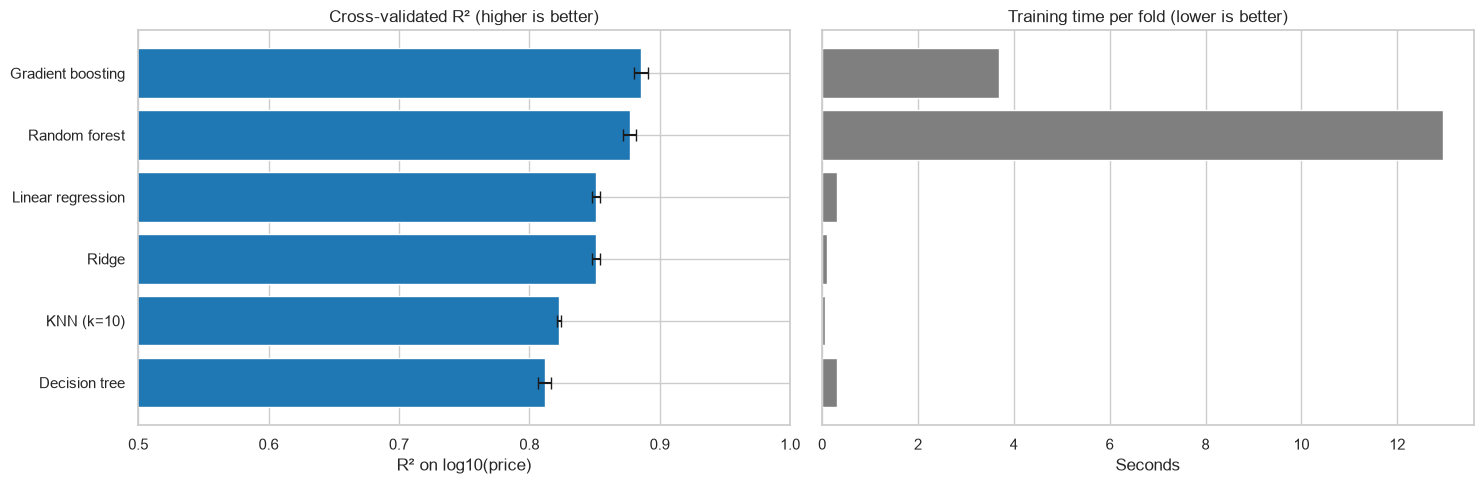

In [19]:
plot_data = regression_results.drop(index="Baseline (mean)").sort_values("R² mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# xerr = error bars of +/- one standard deviation across the 5 folds
axes[0].barh(plot_data.index, plot_data["R² mean"], xerr=plot_data["R² std"], color="tab:blue", capsize=4)
axes[0].set_xlim(0.5, 1)
axes[0].set_title("Cross-validated R² (higher is better)")
axes[0].set_xlabel("R² on log10(price)")

axes[1].barh(plot_data.index, plot_data["fit time (s)"], color="tab:grey")
axes[1].set_title("Training time per fold (lower is better)")
axes[1].set_xlabel("Seconds")
axes[1].set_yticks([])

plt.tight_layout()
save_fig("01_model_comparison")
plt.show()


**Reading the results:**
- **Every model clearly beats the baseline** (R² ≈ 0, typical error ≈ 47%), so they all learned something useful.
- The **linear models** already explain about 85% of the variation (typical error ≈ 14.5%). Linear regression and Ridge are practically identical because we have far more rows (16,556) than columns (82), so regularisation barely matters.
- **KNN** (R² ≈ 0.82) and a **single decision tree** (R² ≈ 0.81) are the weakest models. KNN struggles with the 70 one-hot ZIP code columns, and a single tree gives step-like predictions.
- The two **tree ensembles** are the best: gradient boosting (R² = 0.886, ≈ 12.2% error) and random forest (R² = 0.877, ≈ 12.6% error). The gap between them (≈ 0.009) is less than two standard deviations (≈ 0.005 each), so they are **practically tied**. But gradient boosting trains about **4 times faster**. With equal accuracy, the faster model wins, so we continue with **gradient boosting**.
- The **standard deviations are very small** (≤ 0.005) compared to the gap between the ensembles and the linear models (≈ 0.03), so this part of the ranking is not due to luck.

For our user (an architect comparing design options), the linear model is only about 2 percentage points worse, and each coefficient has a clear meaning. If explaining the price matters more than accuracy, it could still be a reasonable choice.


# 4 Diagnosis and Tuning

## 4.1 Tuning with Validation curve

Figure saved to ..\figures\04_validation_curve.png


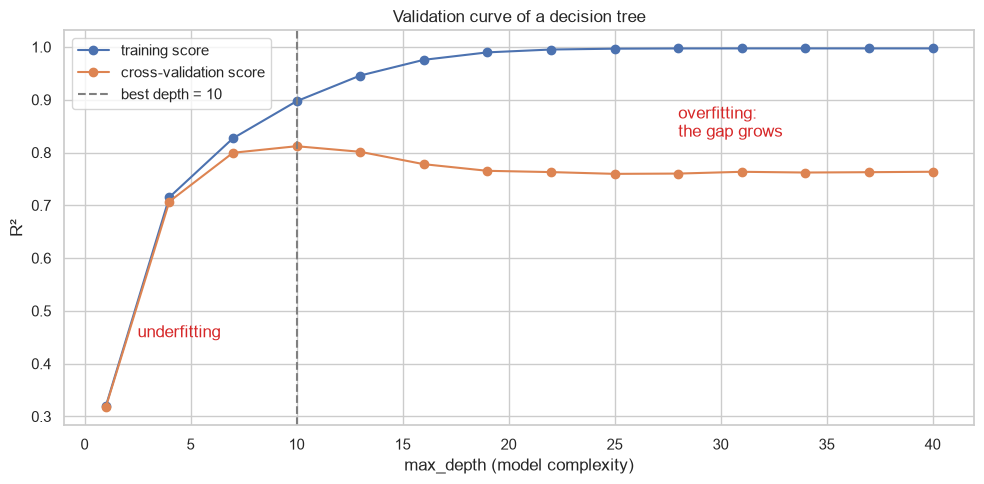

In [20]:
from sklearn.model_selection import validation_curve
groups_train = groups.iloc[train_idx]
depths = np.arange(1, 41, 3)
train_scores, cv_scores = validation_curve(
    house_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE), scale=False),
    X_train, y_train_log,
    param_name="model__max_depth",   # step name + "__" + parameter name
    param_range=depths,
    cv=cv_regression, groups = groups_train, scoring="r2", n_jobs=-1,
)

best_depth = depths[cv_scores.mean(axis=1).argmax()]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_scores.mean(axis=1), marker="o", label="training score")
ax.plot(depths, cv_scores.mean(axis=1), marker="o", label="cross-validation score")
ax.axvline(best_depth, color="grey", linestyle="--", label=f"best depth = {best_depth}")
ax.annotate("underfitting", xy=(2.5, 0.45), fontsize=12, color="tab:red")
ax.annotate("overfitting:\nthe gap grows", xy=(28, 0.83), fontsize=12, color="tab:red")
ax.set_title("Validation curve of a decision tree")
ax.set_xlabel("max_depth (model complexity)")
ax.set_ylabel("R²")
ax.legend()
plt.tight_layout()
save_fig("04_validation_curve")
plt.show()

## 4.2 Hyperparameter tuning with GridSearchCV

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__max_iter": [300],   # number of trees (fixed here)
}

start = time.time()
grid_search = GridSearchCV(
    house_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
    param_grid,
    cv=cv_regression,
    scoring="r2",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train, groups=groups_train)
print(f"Tried {len(grid_search.cv_results_['params'])} combinations x 5 folds in {time.time() - start:.0f} s")
print("Best settings:", grid_search.best_params_)
print(f"Best cross-validated R²: {grid_search.best_score_:.3f} "
      f"(default settings: {regression_results.loc['Gradient boosting', 'R² mean']:.3f})")

Tried 9 combinations x 5 folds in 31 s
Best settings: {'model__learning_rate': 0.05, 'model__max_iter': 300, 'model__max_leaf_nodes': 31}
Best cross-validated R²: 0.867 (default settings: 0.886)


In [22]:
# The full grid as a table: rows = learning_rate, columns = max_leaf_nodes
grid_table = pd.DataFrame(grid_search.cv_results_["params"])
grid_table["R²"] = grid_search.cv_results_["mean_test_score"]
grid_table.pivot(index="model__learning_rate", columns="model__max_leaf_nodes", values="R²")

model__max_leaf_nodes,15,31,63
model__learning_rate,,,
0.05,0.86,0.87,0.87
0.10,0.86,0.87,0.87
0.20,0.86,0.86,0.86


The hyperparameter tuning process did not yield performance improvements. The original Gradient Boosting model achieved a cross-validation $R^2$ of $0.886$, whereas the tuned model scored $0.867$. Consequently, the additional computational cost of the tested tuning configurations was not justified, making the original model the preferred choice for deployment. whereas, the model is experiencing mild overfitting as the training $R^2$ higher the cross validation, meaning the model performs better on data it has already seen.

# 5. Final Evaluation

We review the gradient boosting tuning results, select the final model
using training cross-validation, and evaluate it on the held-out test set.

The model predicts log10-price. We convert predictions back to USD
to report errors in understandable units.

We also draw a separate, small regression tree to illustrate how
tree-based predictions work.

## 5.1 Gradient Boosting Tuning Results

We compare the gradient boosting settings tested in section 4.
The table reports mean cross-validation R² on log-price and its
standard deviation across five folds.

Higher mean R² indicates better validation performance.
Small differences should be considered alongside the variation across folds.

In [29]:
# Review the tuning results already calculated in section 4.
gradient_table = pd.DataFrame(grid_search.cv_results_["params"])

gradient_table["Mean CV R²"] = grid_search.cv_results_["mean_test_score"]
gradient_table["CV standard deviation"] = grid_search.cv_results_[
    "std_test_score"
]

gradient_table = gradient_table.rename(columns={
    "model__learning_rate": "Learning rate",
    "model__max_leaf_nodes": "Maximum leaf nodes",
    "model__max_iter": "Maximum iterations",
})

display(
    gradient_table.sort_values("Mean CV R²", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Learning rate,Maximum iterations,Maximum leaf nodes,Mean CV R²,CV standard deviation
0,0.05,300,31,0.87,0.01
1,0.05,300,63,0.87,0.01
2,0.10,300,63,0.87,0.01
3,0.10,300,31,0.87,0.01
4,0.10,300,15,0.86,0.01
5,0.20,300,31,0.86,0.01
6,0.20,300,63,0.86,0.01
7,0.05,300,15,0.86,0.01
8,0.20,300,15,0.86,0.01


## 5.2 Final Model Selection and Test Results

We select between the default and tuned gradient boosting models using
cross-validation scores from the training data only.

We fit the selected model on the full training set and evaluate it
on the held-out test set. Test results are not used to choose the model.

We report:
- MAE: average absolute error in USD.
- RMSE: an error measure that gives greater weight to large errors.
- R²: performance relative to predicting the mean.
- MAPE: average absolute percentage error.
- Overestimated: percentage of predictions above the actual sale price.
- Within ±20%: percentage of predictions within 20% of the actual price.

We report log-price R² separately so it can be compared with section 3.

In [30]:
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)

# Compare training cross-validation scores on the same target: log10-price.
default_cv_r2 = regression_results.loc[
    "Gradient boosting", "R² mean"
]
tuned_cv_r2 = grid_search.best_score_

if tuned_cv_r2 > default_cv_r2:
    selected_name = "Tuned gradient boosting"
    selected_pipeline = grid_search.best_estimator_
    selected_cv_r2 = tuned_cv_r2
else:
    selected_name = "Default gradient boosting"
    selected_pipeline = regression_pipelines["Gradient boosting"]
    selected_cv_r2 = default_cv_r2

# Fit the selected pipeline on training data only.
best_house_model = clone(selected_pipeline)
best_house_model.fit(X_train, y_train_log)

# Predict log10-price, then convert back to USD.
predicted_log = best_house_model.predict(X_test)
predicted_usd = 10 ** predicted_log
actual_usd = y_test.to_numpy()

# Baseline: always predict the mean training log-price.
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train_log)
baseline_usd = 10 ** baseline_model.predict(X_test)


def evaluate_prices(actual, predicted):
    return {
        "MAE (USD)": mean_absolute_error(actual, predicted),
        "RMSE (USD)": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R² (USD)": r2_score(actual, predicted),
        "MAPE (%)": mean_absolute_percentage_error(
            actual, predicted
        ) * 100,
        "Overestimated (%)": np.mean(predicted > actual) * 100,
        "Within ±20% (%)": np.mean(
            np.abs(predicted - actual) / actual <= 0.20
        ) * 100,
    }


test_results = pd.DataFrame({
    "Baseline": evaluate_prices(actual_usd, baseline_usd),
    selected_name: evaluate_prices(actual_usd, predicted_usd),
}).T

print(f"Selected model: {selected_name}")
print(f"Training CV R² on log-price: {selected_cv_r2:.3f}")
print(
    f"Test R² on log-price: "
    f"{r2_score(y_test_log, predicted_log):.3f}"
)

display(test_results.round(2))

Selected model: Default gradient boosting
Training CV R² on log-price: 0.886
Test R² on log-price: 0.886


,MAE (USD),RMSE (USD),R² (USD),MAPE (%),Overestimated (%),Within ±20% (%)
Baseline,"196,280.74","284,044.93",-0.04,40.50,51.94,31.83
Default gradient boosting,"60,200.51","98,383.87",0.88,11.59,50.74,83.70


## 5.3 Prediction and Error Plots

The first plot compares predicted and actual prices.
Points on the dashed diagonal represent perfect predictions.
Points above the line are overestimated; points below it are underestimated.

The second plot shows percentage errors.
Positive values indicate overestimation, and negative values indicate
underestimation.

Figure saved to ..\figures\05_final_evaluation.png


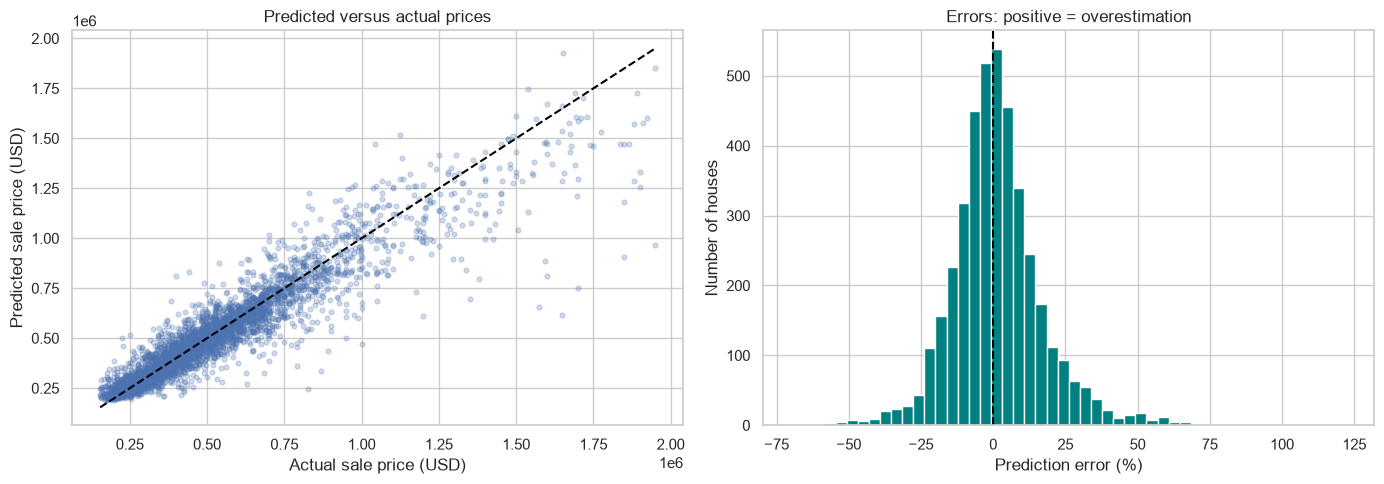

In [31]:
percentage_error = (
    (predicted_usd - actual_usd) / actual_usd * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: predicted versus actual prices.
axes[0].scatter(
    actual_usd,
    predicted_usd,
    alpha=0.25,
    s=12,
)

lower = min(actual_usd.min(), predicted_usd.min())
upper = max(actual_usd.max(), predicted_usd.max())

axes[0].plot(
    [lower, upper],
    [lower, upper],
    "--",
    color="black",
)

axes[0].set_xlabel("Actual sale price (USD)")
axes[0].set_ylabel("Predicted sale price (USD)")
axes[0].set_title("Predicted versus actual prices")

# Plot 2: percentage errors.
axes[1].hist(
    percentage_error,
    bins=50,
    color="teal",
    edgecolor="white",
)

axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("Prediction error (%)")
axes[1].set_ylabel("Number of houses")
axes[1].set_title("Errors: positive = overestimation")

plt.tight_layout()
save_fig("05_final_evaluation")
plt.show()

In [32]:
final_metrics = test_results.loc[selected_name]

mae_reduction = (
    1
    - final_metrics["MAE (USD)"]
    / test_results.loc["Baseline", "MAE (USD)"]
) * 100

print(f"Selected model: {selected_name}")
print(
    f"Average absolute error: "
    f"${final_metrics['MAE (USD)']:,.0f}"
)
print(
    f"MAE reduction compared with baseline: "
    f"{mae_reduction:.1f}%"
)
print(
    f"Average absolute percentage error: "
    f"{final_metrics['MAPE (%)']:.2f}%"
)
print(
    f"Predictions within ±20%: "
    f"{final_metrics['Within ±20% (%)']:.2f}%"
)
print(
    f"Prices overestimated: "
    f"{final_metrics['Overestimated (%)']:.2f}%"
)

Selected model: Default gradient boosting
Average absolute error: $60,201
MAE reduction compared with baseline: 69.3%
Average absolute percentage error: 11.59%
Predictions within ±20%: 83.70%
Prices overestimated: 50.74%


### Reading the Results

The numerical summary reports how much the selected model improves
on the baseline and how often its predictions are close to actual prices.

The plots help identify errors that an average score can hide.
In particular, expensive houses may have larger dollar errors.

Similar cross-validation and test scores suggest consistent performance
across these evaluations. They do not establish reliability in future
markets or other locations.

Overestimation frequency should be considered alongside the size of
those errors, especially because overestimation is costly for our user.

## 5.4 A Simple Regression Tree

We train a small regression tree using living area, grade, bathrooms
and year built to illustrate how a tree makes predictions.

This is a separate explanatory model. It does not represent the complete
gradient boosting model, which combines many trees.



Figure saved to ..\figures\05_readable_regression_tree.png


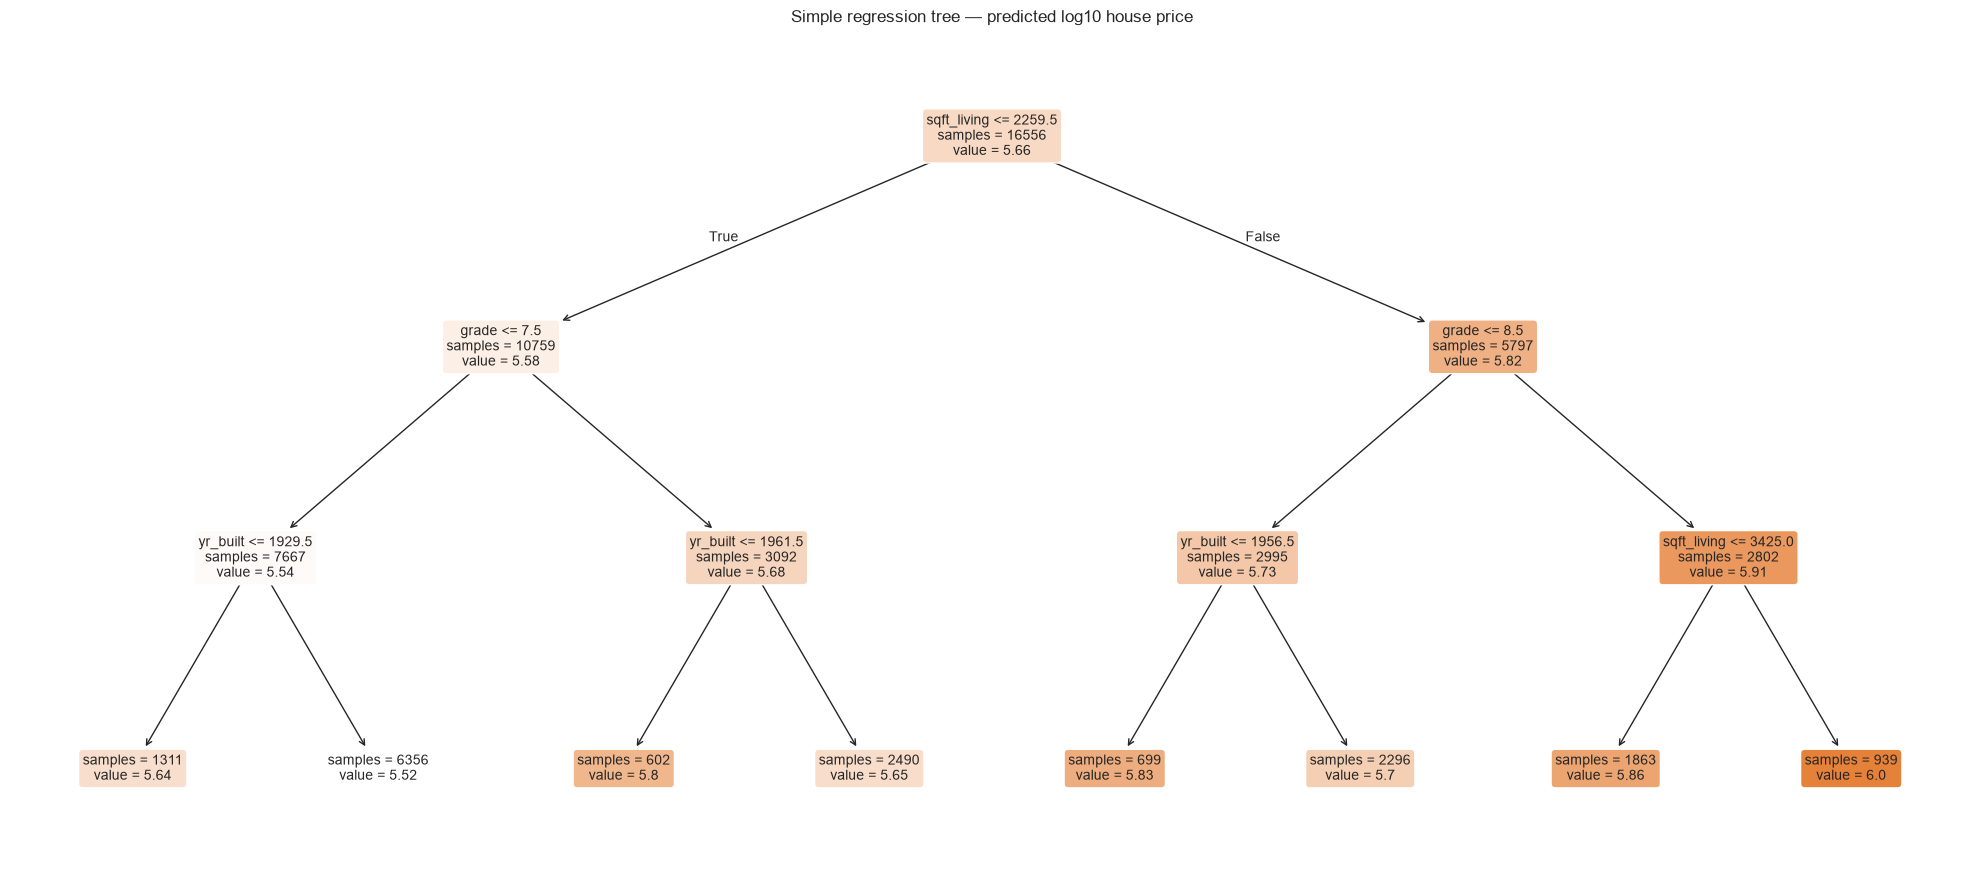

In [33]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

# Use four features to keep the diagram understandable.
tree_features = [
    "sqft_living",
    "grade",
    "bathrooms",
    "yr_built",
]

readable_tree = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=50,
    random_state=RANDOM_STATE,
)

readable_tree.fit(
    X_train[tree_features],
    y_train_log,
)

fig, ax = plt.subplots(figsize=(20, 9))

plot_tree(
    readable_tree,
    feature_names=tree_features,
    filled=True,
    rounded=True,
    impurity=False,
    precision=2,
    fontsize=10,
    ax=ax,
)

ax.set_title(
    "Simple regression tree — predicted log10 house price"
)

plt.tight_layout()
save_fig("05_readable_regression_tree")
plt.show()

# 6 Interpretation

In [25]:
# 1) Coefficients of the Ridge model (refit on the full training set)
ridge_pipeline = house_pipeline(Ridge()).fit(X_train, y_train)
coefficients = pd.Series(
    ridge_pipeline.named_steps["model"].coef_,
    index=ridge_pipeline.named_steps["preprocess"].get_feature_names_out(),
)

# Only the numeric features (the 81 city columns would make the plot unreadable)
numeric_coefficients = coefficients[coefficients.index.str.startswith("numeric__")]
numeric_coefficients.index = numeric_coefficients.index.str.replace("numeric__", "")
numeric_coefficients.sort_values()

yr_built        -26,181.22
long            -20,155.40
sqft_basement   -18,924.20
bedrooms        -14,003.75
floors          -12,243.10
yr_renovated      9,844.46
sqft_lot         12,560.35
bathrooms        14,624.19
condition        15,821.64
lat              20,868.40
grade            77,354.03
sqft_living     126,660.11
dtype: float64

# 7. Save and Reuse the Model

We save the preprocessing pipeline and trained model together, so we can
reload them and make predictions without training again.

The model predicts log10-price. We convert its output back to USD.

We demonstrate reuse with one house from the existing test set.
This is an example of loading and predicting, not a new independent evaluation.

In [ ]:
# Save the trained pipeline and the information needed to use it.
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "king_county_house_price.joblib"

model_bundle = {
    "pipeline": best_house_model,
    "feature_columns": X_train.columns.tolist(),
    "target_transform": "log10",
    "currency": "USD",
    "selected_model": selected_name,
}

joblib.dump(model_bundle, model_path)
print(f"Model saved to: {model_path}")

# Load the saved model.
loaded_bundle = joblib.load(model_path)
loaded_model = loaded_bundle["pipeline"]

# Use one test house to demonstrate a prediction.
example_house = X_test.iloc[[0]].copy()
predicted_log_price = loaded_model.predict(example_house)[0]
predicted_price = 10 ** predicted_log_price

display(example_house)
print(f"Predicted price: ${predicted_price:,.0f}")
print(f"Actual price:    ${y_test.iloc[0]:,.0f}")

# Confirm that saving and loading did not change the predictions.
np.testing.assert_allclose(
    loaded_model.predict(X_test.iloc[:5]),
    best_house_model.predict(X_test.iloc[:5]),
)
print("Reload check passed.")

Model saved to: ..\models\king_county_house_price.joblib


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_basement,yr_built,yr_renovated,zipcode,lat,long
3,4,3.00,1960,5000,1.00,5,7,910,1965,0,98136,47.52,-122.39


Predicted price: $494,959
Actual price:    $604,000
Reload check passed.


# 8. Limitations


## Filtered Dataset
Extreme observations were removed during Day 1 cleaning.
Our results therefore apply to the filtered dataset and may not represent
unusual or very expensive properties.

## Larger Errors for Expensive Houses
The prediction plot shows larger dollar errors among expensive houses.
The overall average error can hide differences between price groups.

## Overestimation Risk
The model overestimated 50.74% of test prices. Since overestimation is
especially costly for our use case, we should also investigate the size
of these errors. Frequency alone does not measure their financial impact.

## Design Changes Are Not Proven Causes
Changing an input, such as floor area or grade, may change the prediction.
This does not prove that making that design change would increase the
actual sale price by the same amount.

## Generalisation and Professional Judgement
Grouping by house ID prevents the same house appearing in both training
and test sets. However, this does not test performance in future markets
or completely new geographical areas.
